# 🌾 Crop Recommendation — Cleaned Feature Set

**Target:** `CROPS`

**Dropped features** (leakage / reference-limit columns):
`TYPE_OF_CROP`, `SOIL_PH_HIGH`, `CROPDURATION_MAX`, `MAX_TEMP`, `WATERREQUIRED_MAX`, `RELATIVE_HUMIDITY_MAX`, `N_MAX`, `P_MAX`, `K_MAX`

**Features used**
- Categorical: `SOIL`, `SEASON`, `SOWN`, `HARVESTED`, `WATER_SOURCE`
- Numeric: `SOIL_PH`, `CROPDURATION`, `TEMP`, `WATERREQUIRED`, `RELATIVE_HUMIDITY`, `N`, `P`, `K`

⚠️ The CSV is loaded as `"Crop_Dataset.csv"` in Cell 2 — keep it in the same folder as this notebook (or edit that one line).

Preprocessing uses a `ColumnTransformer` (`StandardScaler` + `OneHotEncoder`) inside every model `Pipeline`. The last cell prints the **Best Crop** for a new input.

## Cell 1 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import time
import pickle
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from xgboost import XGBClassifier


## Cell 2 — Load Dataset

In [2]:
crop = pd.read_csv("Crop_Dataset.csv")

print("Dataset Shape:", crop.shape)

crop.head()

Dataset Shape: (57000, 23)


,CROPS,TYPE_OF_CROP,SOIL,SEASON,SOWN,HARVESTED,WATER_SOURCE,SOIL_PH,SOIL_PH_HIGH,CROPDURATION,...,WATERREQUIRED,WATERREQUIRED_MAX,RELATIVE_HUMIDITY,RELATIVE_HUMIDITY_MAX,N,N_MAX,P,P_MAX,K,K_MAX
0,rice,cereals,Alluvial soil,kharif,Jun,Sep,irrigated,7.6,8.0,116.9,...,2462.3,2500,73.8,80,82.4,100,40.7,60,42.2,60
1,rice,cereals,Loamy soil,kharif,Jul,Oct,rainfed,6.2,8.0,117.9,...,1237.5,2500,60.9,80,90.5,100,51.3,60,46.2,60
2,rice,cereals,Clay soil,kharif,Jun,Sep,irrigated,6.7,8.0,117.7,...,1075.1,2500,67.5,80,86.2,100,50.7,60,44.4,60
3,rice,cereals,Alluvial soil,kharif,Jul,Oct,rainfed,6.1,8.0,149.8,...,1549.9,2500,73.6,80,91.3,100,51.3,60,44.5,60
4,rice,cereals,Loamy soil,kharif,Jun,Sep,irrigated,8.0,8.0,131.7,...,1306.4,2500,60.3,80,81.3,100,48.6,60,51.0,60


## Cell 3 — Basic Dataset Check

In [3]:
print("Dataset Information:")
crop.info()

print("\nMissing Values:")
print(crop.isnull().sum())

print("\nDuplicate Rows:")
print(crop.duplicated().sum())

print("\nNumber of Crop Classes:")
print(crop["CROPS"].nunique())

print("\nClass Distribution:")
print(crop["CROPS"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57000 entries, 0 to 56999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CROPS                  57000 non-null  object 
 1   TYPE_OF_CROP           57000 non-null  object 
 2   SOIL                   57000 non-null  object 
 3   SEASON                 57000 non-null  object 
 4   SOWN                   57000 non-null  object 
 5   HARVESTED              57000 non-null  object 
 6   WATER_SOURCE           57000 non-null  object 
 7   SOIL_PH                57000 non-null  float64
 8   SOIL_PH_HIGH           57000 non-null  float64
 9   CROPDURATION           57000 non-null  float64
 10  CROPDURATION_MAX       57000 non-null  int64  
 11  TEMP                   57000 non-null  float64
 12  MAX_TEMP               57000 non-null  int64  
 13  WATERREQUIRED          57000 non-null  float64
 14  WATERREQUIRED_MAX      57000 non-

## Cell 4 — Define Feature Groups
The 9 listed columns are removed here, so they never reach the models.

In [4]:
# Columns removed (leakage / reference-limit columns)
dropped_features = [
    "TYPE_OF_CROP",
    "SOIL_PH_HIGH",
    "CROPDURATION_MAX",
    "MAX_TEMP",
    "WATERREQUIRED_MAX",
    "RELATIVE_HUMIDITY_MAX",
    "N_MAX",
    "P_MAX",
    "K_MAX"
]

crop = crop.drop(columns=dropped_features)

categorical_features = [
    "SOIL",
    "SEASON",
    "SOWN",
    "HARVESTED",
    "WATER_SOURCE"
]

numeric_features = [
    "SOIL_PH",
    "CROPDURATION",
    "TEMP",
    "WATERREQUIRED",
    "RELATIVE_HUMIDITY",
    "N",
    "P",
    "K"
]

all_features = numeric_features + categorical_features

X = crop[all_features]
y = crop["CROPS"]

print("Dropped:", dropped_features)
print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nCategorical unique values:")
for col in categorical_features:
    print(f"{col}: {crop[col].nunique()} unique ->", crop[col].unique())

Dropped: ['TYPE_OF_CROP', 'SOIL_PH_HIGH', 'CROPDURATION_MAX', 'MAX_TEMP', 'WATERREQUIRED_MAX', 'RELATIVE_HUMIDITY_MAX', 'N_MAX', 'P_MAX', 'K_MAX']
X Shape: (57000, 13)
y Shape: (57000,)

Categorical unique values:
SOIL: 34 unique -> ['Alluvial soil' 'Loamy soil' 'Clay soil' 'well-drained soil' 'Red soil'
 'clay Loamy soil' 'sandy loamy\xa0soil' 'Black Soil' 'Sandy soil'
 'shallow Black Soil' 'sandy Loamy soil' 'black cotton soil'
 'Sandy\xa0soil' '\xa0cotton\xa0soil' 'Sandy soil\xa0' 'medium Black Soil'
 'heavy Black Soil' '\xa0light soi' 'heavy soil\xa0' 'deep soil'
 'loamy\xa0soil' 'sandy clay Loamy soil\xa0' 'silty Loamy soil'
 'salty clay Loamy soil' 'red Loamy soil' 'brown Loamy soil'
 'clay Loamy soil ' 'Laterite soil' 'well-drained loamy\xa0soil'
 'light Loamy soil' 'friable soil' 'well-grained deep loamy moist soil'
 'red lateritic Loamy soil' 'rich red Loamy soil']
SEASON: 3 unique -> ['kharif' 'rabi' 'Zaid']
SOWN: 8 unique -> ['Jun' 'Jul' 'Oct' 'Nov' 'Dec' 'Mar' 'Apr' 'May']


## Cell 5 — Encode Target

In [5]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Crop Classes:")

for i, crop_name in enumerate(label_encoder.classes_):
    print(i, "=", crop_name)

Crop Classes:
0 = Cabbage
1 = Pearl millet
2 = annual moringa
3 = ash gourd
4 = beetroot
5 = bengalgram
6 = bhendi
7 = bitter gourd
8 = blackgram
9 = bottle gourd
10 = brinjal
11 = capsicum
12 = carrot
13 = castor
14 = cauliflower
15 = chillies
16 = chowchow
17 = cluster bean
18 = cotton
19 = cowpea
20 = cucumber
21 = elephant foot yam
22 = french bean
23 = gingely
24 = greengram
25 = groundnut
26 = horsegram
27 = jute
28 = kudiraivali
29 = maize
30 = muskmelon
31 = onion
32 = panivaragu
33 = peas
34 = pumpkin
35 = radish
36 = ragi
37 = redgram
38 = ribbed gourd
39 = rice
40 = samai
41 = small onion
42 = snake gourd
43 = sorghum
44 = soyabean
45 = sugarbeet
46 = sugarcane
47 = sunflower
48 = sweet potato
49 = tapoica
50 = thinai
51 = tinda
52 = tomato
53 = varagu
54 = vegetable cowpea
55 = watermelon
56 = wheat


## Cell 6 — Train/Test Split
Stratified so every crop class stays balanced across train and test.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (45600, 13)
Testing Data: (11400, 13)


## Cell 7 — Preprocessor
`ColumnTransformer` scales numeric columns and one-hot encodes categorical columns. `handle_unknown="ignore"` prevents a crash if a new/unseen category shows up at prediction time.

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    sparse_threshold=0
)

## Cell 8 — Baseline Models
Each wrapped with the shared `preprocessor` so encoding/scaling is fit only on training data.

In [8]:
baseline_models = {

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GaussianNB())
    ]),

    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier())
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ])
}

## Cell 9 — Strong Models

In [9]:
strong_models = {

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]),

    "Extra Trees": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            ExtraTreesClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]),

    "Hist Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=100,
                random_state=42
            )
        )
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=len(label_encoder.classes_),
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            )
        )
    ])
}


## Cell 10 — Combine Models

In [10]:
models = {}

models.update(baseline_models)
models.update(strong_models)

print("Total Models:", len(models))

for name in models:
    print(name)

Total Models: 9
Logistic Regression
Gaussian Naive Bayes
KNN
SVM
Decision Tree
Random Forest
Extra Trees
Hist Gradient Boosting
XGBoost


## Cell 11 — Evaluation Function
Same metrics as before: macro precision/recall/F1, accuracy, 5-fold CV (macro F1), training/validation gap, confusion matrix, timing.

In [11]:
def evaluate_model(name, model):

    # =====================================================
    # TRAINING
    # =====================================================

    start_train = time.perf_counter()

    model.fit(
        X_train,
        y_train
    )

    end_train = time.perf_counter()

    training_time = (
        end_train - start_train
    )


    # =====================================================
    # TRAINING PREDICTION
    # =====================================================

    y_train_pred = model.predict(
        X_train
    )

    train_accuracy = accuracy_score(
        y_train,
        y_train_pred
    )


    # =====================================================
    # VALIDATION / TEST PREDICTION
    # =====================================================

    start_predict = time.perf_counter()

    y_test_pred = model.predict(
        X_test
    )

    end_predict = time.perf_counter()

    inference_time = (
        end_predict - start_predict
    )


    # =====================================================
    # TEST METRICS
    # =====================================================

    accuracy = accuracy_score(
        y_test,
        y_test_pred
    )

    precision_macro = precision_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    )


    # =====================================================
    # TRAINING / VALIDATION GAP
    # =====================================================

    training_validation_gap = (
        train_accuracy - accuracy
    )


    # =====================================================
    # 5-FOLD STRATIFIED CROSS VALIDATION
    # =====================================================

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    cv_mean = cv_scores.mean()

    cv_std = cv_scores.std()


    # =====================================================
    # CONFUSION MATRIX
    # =====================================================

    cm = confusion_matrix(
        y_test,
        y_test_pred
    )


    # =====================================================
    # RETURN ALL RESULTS
    # =====================================================

    return {

        "Model": name,

        "F1 Macro": f1_macro,

        "Accuracy": accuracy,

        "Precision Macro": precision_macro,

        "Recall Macro": recall_macro,

        "CV Mean": cv_mean,

        "CV Std": cv_std,

        "Training Accuracy": train_accuracy,

        "Training Validation Gap":
            training_validation_gap,

        "Training Time":
            training_time,

        "Inference Time":
            inference_time,

        "Confusion Matrix":
            cm,

        "Predictions":
            y_test_pred,

        "Model Object":
            model
    }

## Cell 12 — Train All Models

In [12]:
results = []

for name, model in models.items():

    print(
        "Training:",
        name
    )

    result = evaluate_model(
        name,
        model
    )

    results.append(
        result
    )

print("\nAll models completed.")

Training: Logistic Regression
Training: Gaussian Naive Bayes
Training: KNN
Training: SVM
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: Hist Gradient Boosting
Training: XGBoost

All models completed.


## Cell 13 — Create Result Table

In [13]:
results_df = pd.DataFrame([

    {
        "Model": r["Model"],

        "F1 Macro": r["F1 Macro"],

        "Accuracy": r["Accuracy"],

        "Precision Macro":
            r["Precision Macro"],

        "Recall Macro":
            r["Recall Macro"],

        "CV Mean":
            r["CV Mean"],

        "CV Std":
            r["CV Std"],

        "Training Accuracy":
            r["Training Accuracy"],

        "Training Validation Gap":
            r["Training Validation Gap"],

        "Training Time":
            r["Training Time"],

        "Inference Time":
            r["Inference Time"]
    }

    for r in results
])

results_df

,Model,F1 Macro,Accuracy,Precision Macro,Recall Macro,CV Mean,CV Std,Training Accuracy,Training Validation Gap,Training Time,Inference Time
0,Logistic Regression,0.994572,0.994561,0.994629,0.994561,0.994414,0.000808,0.995285,0.000724,5.026064,0.030186
1,Gaussian Naive Bayes,0.966074,0.964298,0.978518,0.964298,0.965955,0.002449,0.964298,0.000000,0.185793,0.527278
2,KNN,0.989819,0.989825,0.990073,0.989825,0.988232,0.000743,0.993947,0.004123,0.182957,6.909938
3,SVM,0.994833,0.994825,0.994979,0.994825,0.994743,0.000357,0.995680,0.000855,18.729861,44.573224
4,Decision Tree,0.998948,0.998947,0.998953,0.998947,0.998421,0.000266,1.000000,0.001053,0.816398,0.023467
5,Random Forest,0.999912,0.999912,0.999913,0.999912,0.999890,0.000098,1.000000,0.000088,6.624622,0.950177
6,Extra Trees,0.998860,0.998860,0.998884,0.998860,0.999123,0.000098,1.000000,0.001140,7.714226,0.875323
7,Hist Gradient Boosting,0.999649,0.999649,0.999653,0.999649,0.999693,0.000145,0.999978,0.000329,19.489652,0.624467
8,XGBoost,0.999912,0.999912,0.999913,0.999912,0.999846,0.000088,1.000000,0.000088,48.242205,0.266586


## Cell 14 — ⭐ Composite Score

Weights: F1 Macro 30%, Accuracy 20%, Precision Macro 15%, Recall Macro 15%, CV Mean 20%.

In [14]:
results_df["Composite Score"] = (

    0.30 * results_df["F1 Macro"]

    +

    0.20 * results_df["Accuracy"]

    +

    0.15 * results_df["Precision Macro"]

    +

    0.15 * results_df["Recall Macro"]

    +

    0.20 * results_df["CV Mean"]
)

## Cell 15 — Gap Penalty & Stability Score

In [15]:
results_df["Gap Penalty"] = (
    results_df["Training Validation Gap"]
    .abs()
)

results_df["Stability Score"] = (
    1 -
    results_df["Gap Penalty"]
)

## Cell 16 — Final Score
90% Composite Score + 10% Stability Score.

In [16]:
results_df["Final Score"] = (

    0.90 * results_df["Composite Score"]

    +

    0.10 * results_df["Stability Score"]
)

## Cell 17 — Rank Models

In [17]:
results_df = results_df.sort_values(
    by="Final Score",
    ascending=False
)

results_df = results_df.reset_index(
    drop=True
)

results_df["Rank"] = (
    results_df.index + 1
)

results_df[
    [
        "Rank",
        "Model",
        "F1 Macro",
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "CV Mean",
        "CV Std",
        "Training Accuracy",
        "Training Validation Gap",
        "Composite Score",
        "Stability Score",
        "Final Score"
    ]
]

,Rank,Model,F1 Macro,Accuracy,Precision Macro,Recall Macro,CV Mean,CV Std,Training Accuracy,Training Validation Gap,Composite Score,Stability Score,Final Score
0,1,Random Forest,0.999912,0.999912,0.999913,0.999912,0.999890,0.000098,1.000000,0.000088,0.999908,0.999912,0.999908
1,2,XGBoost,0.999912,0.999912,0.999913,0.999912,0.999846,0.000088,1.000000,0.000088,0.999899,0.999912,0.999900
2,3,Hist Gradient Boosting,0.999649,0.999649,0.999653,0.999649,0.999693,0.000145,0.999978,0.000329,0.999659,0.999671,0.999660
3,4,Extra Trees,0.998860,0.998860,0.998884,0.998860,0.999123,0.000098,1.000000,0.001140,0.998916,0.998860,0.998911
4,5,Decision Tree,0.998948,0.998947,0.998953,0.998947,0.998421,0.000266,1.000000,0.001053,0.998843,0.998947,0.998854
5,6,SVM,0.994833,0.994825,0.994979,0.994825,0.994743,0.000357,0.995680,0.000855,0.994834,0.999145,0.995265
6,7,Logistic Regression,0.994572,0.994561,0.994629,0.994561,0.994414,0.000808,0.995285,0.000724,0.994545,0.999276,0.995019
7,8,KNN,0.989819,0.989825,0.990073,0.989825,0.988232,0.000743,0.993947,0.004123,0.989542,0.995877,0.990175
8,9,Gaussian Naive Bayes,0.966074,0.964298,0.978518,0.964298,0.965955,0.002449,0.964298,0.000000,0.967295,1.000000,0.970566


## Cell 18 — Percentage Result

In [18]:
display_df = results_df.copy()

percentage_columns = [
    "F1 Macro",
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "CV Mean",
    "Composite Score",
    "Stability Score",
    "Final Score"
]

for col in percentage_columns:

    display_df[col] = (
        display_df[col] * 100
    ).round(2)

display_df[
    [
        "Rank",
        "Model",
        "F1 Macro",
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "CV Mean",
        "CV Std",
        "Training Accuracy",
        "Training Validation Gap",
        "Composite Score",
        "Stability Score",
        "Final Score"
    ]
]

,Rank,Model,F1 Macro,Accuracy,Precision Macro,Recall Macro,CV Mean,CV Std,Training Accuracy,Training Validation Gap,Composite Score,Stability Score,Final Score
0,1,Random Forest,99.99,99.99,99.99,99.99,99.99,0.000098,1.000000,0.000088,99.99,99.99,99.99
1,2,XGBoost,99.99,99.99,99.99,99.99,99.98,0.000088,1.000000,0.000088,99.99,99.99,99.99
2,3,Hist Gradient Boosting,99.96,99.96,99.97,99.96,99.97,0.000145,0.999978,0.000329,99.97,99.97,99.97
3,4,Extra Trees,99.89,99.89,99.89,99.89,99.91,0.000098,1.000000,0.001140,99.89,99.89,99.89
4,5,Decision Tree,99.89,99.89,99.90,99.89,99.84,0.000266,1.000000,0.001053,99.88,99.89,99.89
5,6,SVM,99.48,99.48,99.50,99.48,99.47,0.000357,0.995680,0.000855,99.48,99.91,99.53
6,7,Logistic Regression,99.46,99.46,99.46,99.46,99.44,0.000808,0.995285,0.000724,99.45,99.93,99.50
7,8,KNN,98.98,98.98,99.01,98.98,98.82,0.000743,0.993947,0.004123,98.95,99.59,99.02
8,9,Gaussian Naive Bayes,96.61,96.43,97.85,96.43,96.60,0.002449,0.964298,0.000000,96.73,100.00,97.06


## Cell 19 — 🏆 Best Model

In [19]:
best_model_name = results_df.iloc[0]["Model"]

best_result = next(
    r for r in results
    if r["Model"] == best_model_name
)

best_model = best_result["Model Object"]

print("=" * 60)

print("🏆 BEST MODEL")

print("=" * 60)

print(
    "Model:",
    best_model_name
)

print(
    f"F1 Macro: "
    f"{results_df.iloc[0]['F1 Macro'] * 100:.2f}%"
)

print(
    f"Accuracy: "
    f"{results_df.iloc[0]['Accuracy'] * 100:.2f}%"
)

print(
    f"Precision Macro: "
    f"{results_df.iloc[0]['Precision Macro'] * 100:.2f}%"
)

print(
    f"Recall Macro: "
    f"{results_df.iloc[0]['Recall Macro'] * 100:.2f}%"
)

print(
    f"CV Score: "
    f"{results_df.iloc[0]['CV Mean'] * 100:.2f}%"
)

print(
    f"Training/Validation Gap: "
    f"{results_df.iloc[0]['Training Validation Gap'] * 100:.2f}%"
)

print(
    f"Final Score: "
    f"{results_df.iloc[0]['Final Score'] * 100:.2f}%"
)

print("=" * 60)

🏆 BEST MODEL
Model: Random Forest
F1 Macro: 99.99%
Accuracy: 99.99%
Precision Macro: 99.99%
Recall Macro: 99.99%
CV Score: 99.99%
Training/Validation Gap: 0.01%
Final Score: 99.99%


## Cell 20 — F1 Macro Comparison

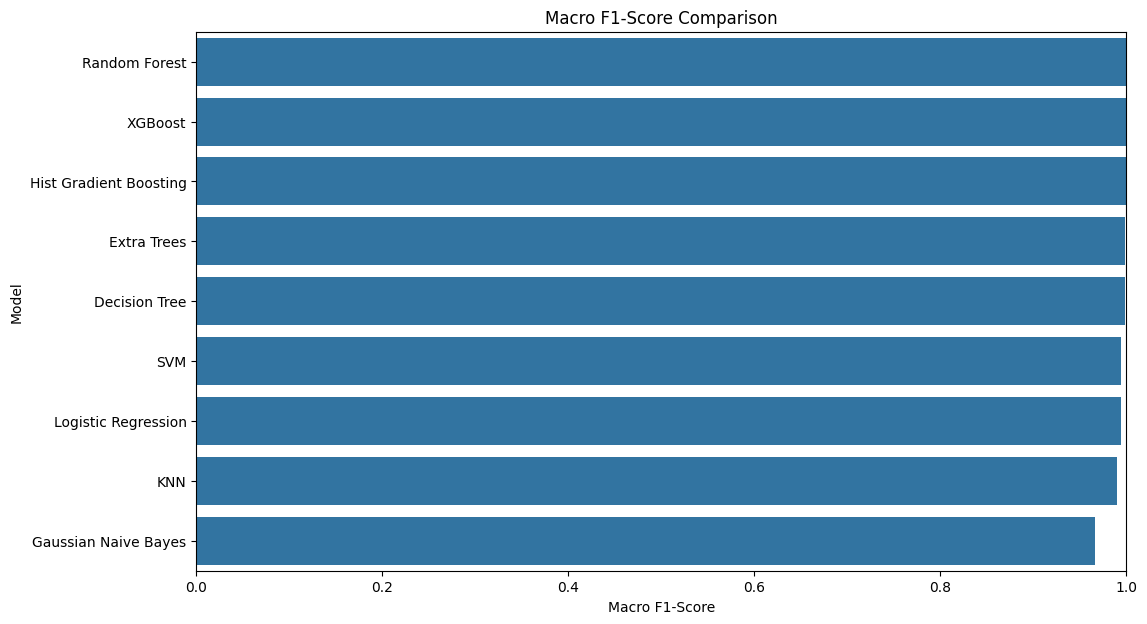

In [20]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="F1 Macro",
    y="Model"
)

plt.title("Macro F1-Score Comparison")
plt.xlabel("Macro F1-Score")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

## Cell 21 — Accuracy Comparison

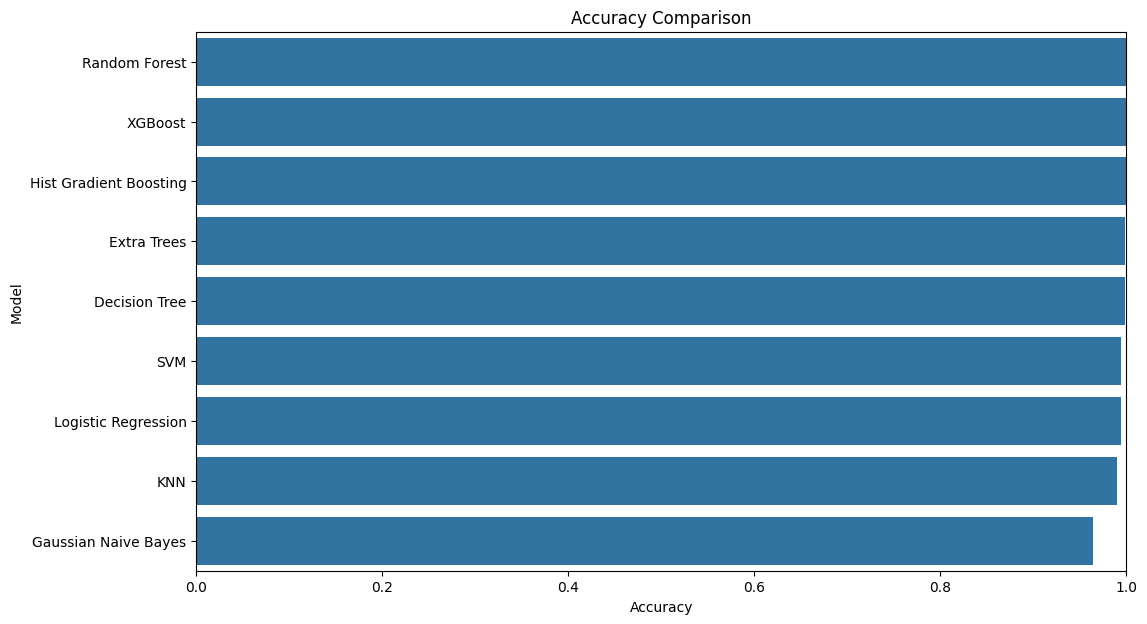

In [21]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.title("Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

## Cell 22 — Precision Macro

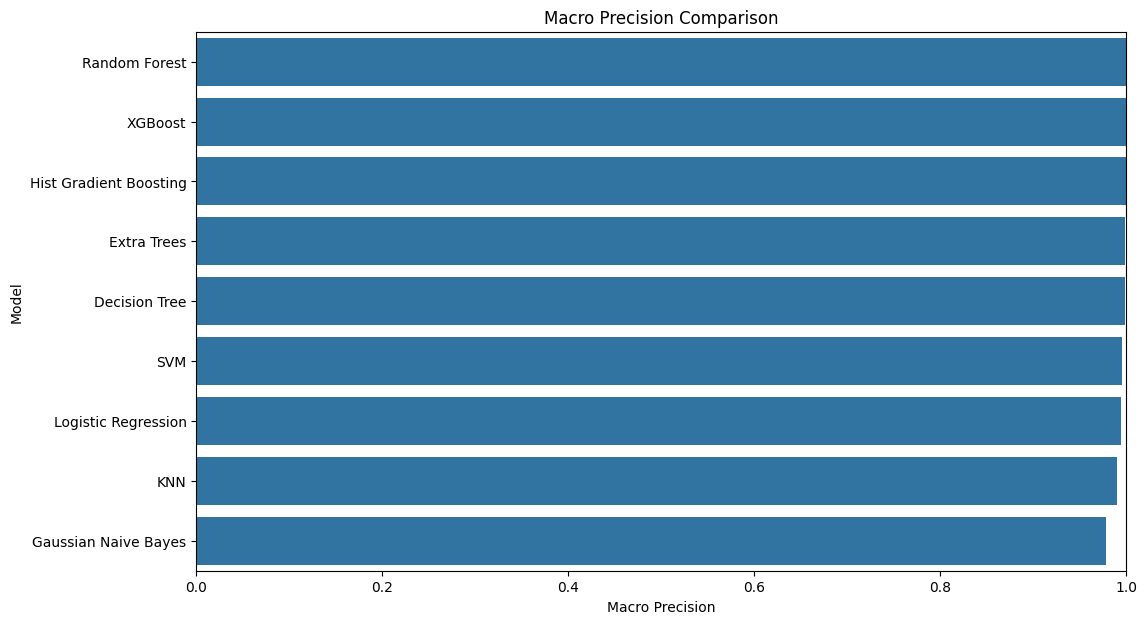

In [22]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="Precision Macro",
    y="Model"
)

plt.title("Macro Precision Comparison")
plt.xlabel("Macro Precision")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

## Cell 23 — Recall Macro

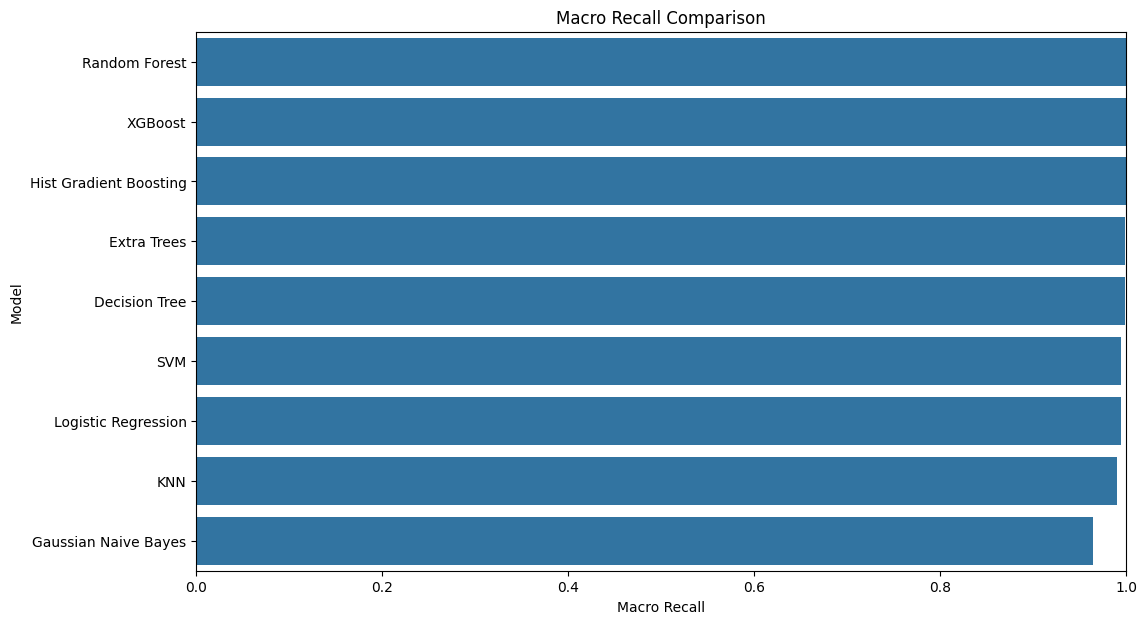

In [23]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="Recall Macro",
    y="Model"
)

plt.title("Macro Recall Comparison")
plt.xlabel("Macro Recall")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

## Cell 24 — Cross Validation

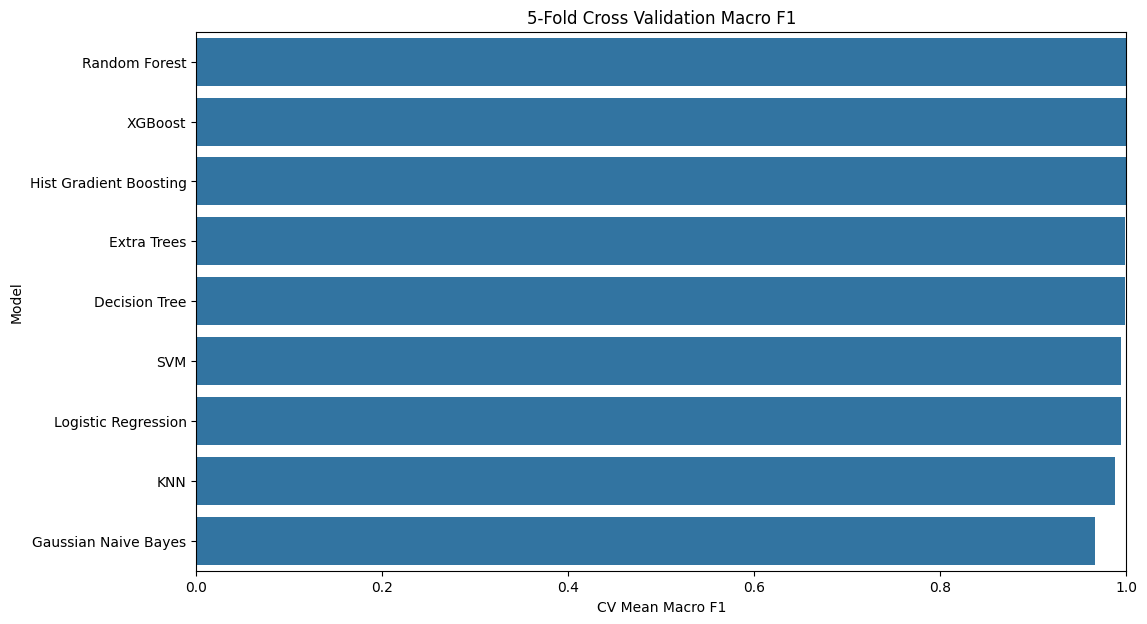

In [24]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="CV Mean",
    y="Model"
)

plt.title("5-Fold Cross Validation Macro F1")
plt.xlabel("CV Mean Macro F1")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

## Cell 25 — Final Score

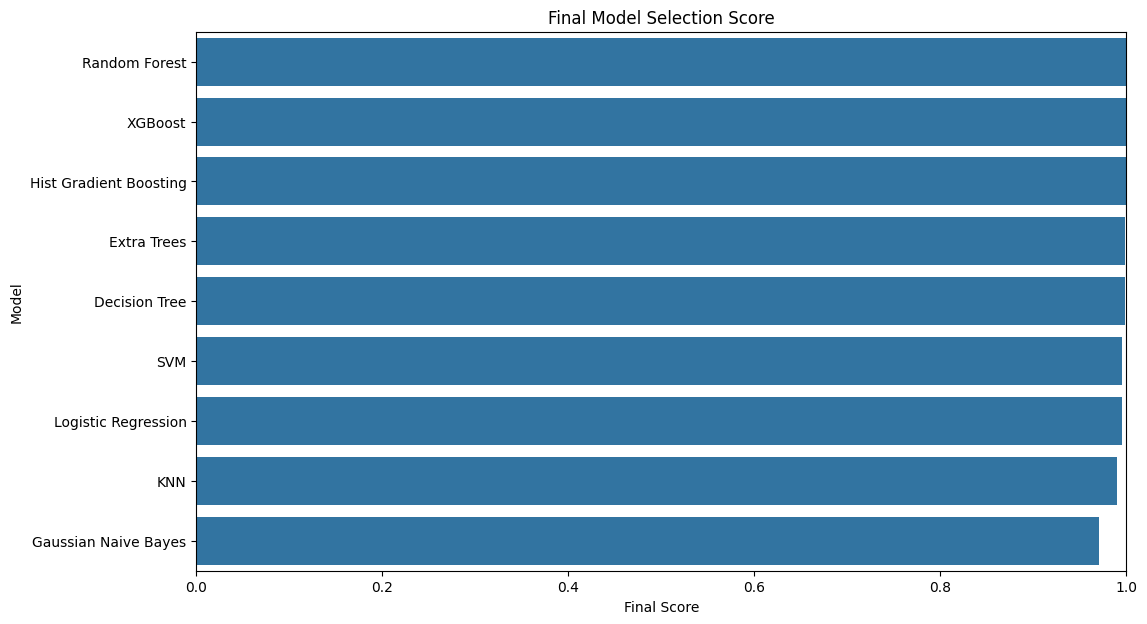

In [25]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="Final Score",
    y="Model"
)

plt.title("Final Model Selection Score")
plt.xlabel("Final Score")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

## Cell 26 — Training/Validation Gap

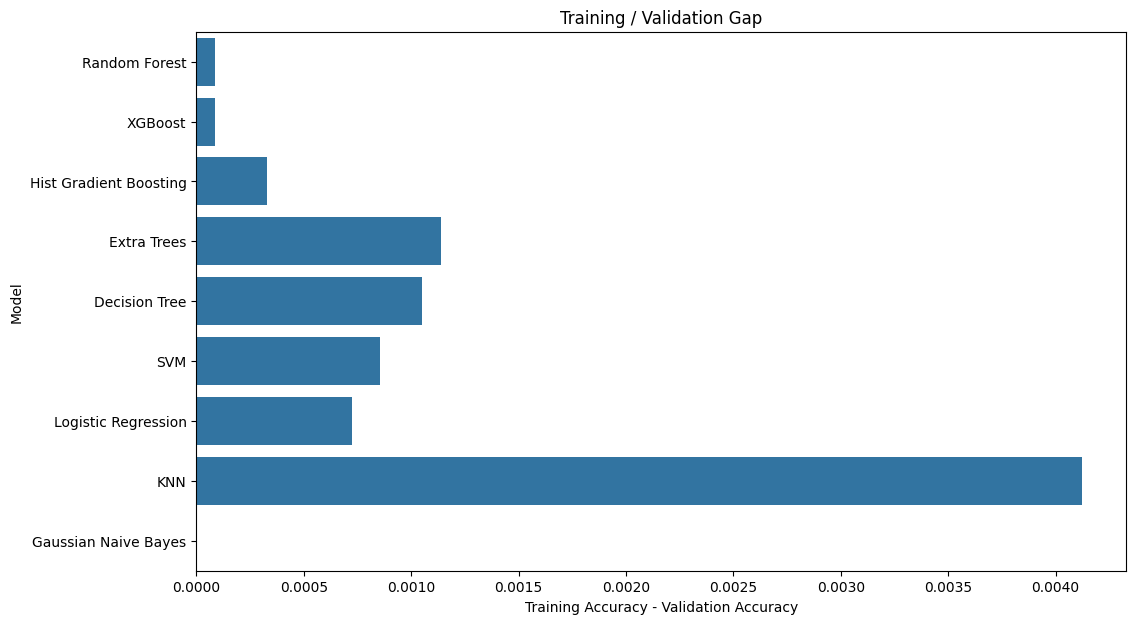

In [26]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="Training Validation Gap",
    y="Model"
)

plt.title("Training / Validation Gap")
plt.xlabel("Training Accuracy - Validation Accuracy")
plt.ylabel("Model")

plt.show()

## Cell 27 — Best Model Classification Report

In [27]:
best_predictions = best_result[
    "Predictions"
]

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                   precision    recall  f1-score   support

          Cabbage       1.00      1.00      1.00       200
     Pearl millet       1.00      1.00      1.00       200
   annual moringa       1.00      1.00      1.00       200
        ash gourd       1.00      1.00      1.00       200
         beetroot       1.00      1.00      1.00       200
       bengalgram       1.00      1.00      1.00       200
           bhendi       1.00      1.00      1.00       200
     bitter gourd       1.00      1.00      1.00       200
        blackgram       1.00      1.00      1.00       200
     bottle gourd       1.00      1.00      1.00       200
          brinjal       1.00      1.00      1.00       200
         capsicum       1.00      1.00      1.00       200
           carrot       1.00      1.00      1.00       200
           castor       1.00      1.00      1.00       200
      cauliflower       1.00      1.00      1.00       200
         chillies       1.00      1.00      1.00       

## Cell 28 — 🟦 Confusion Matrix

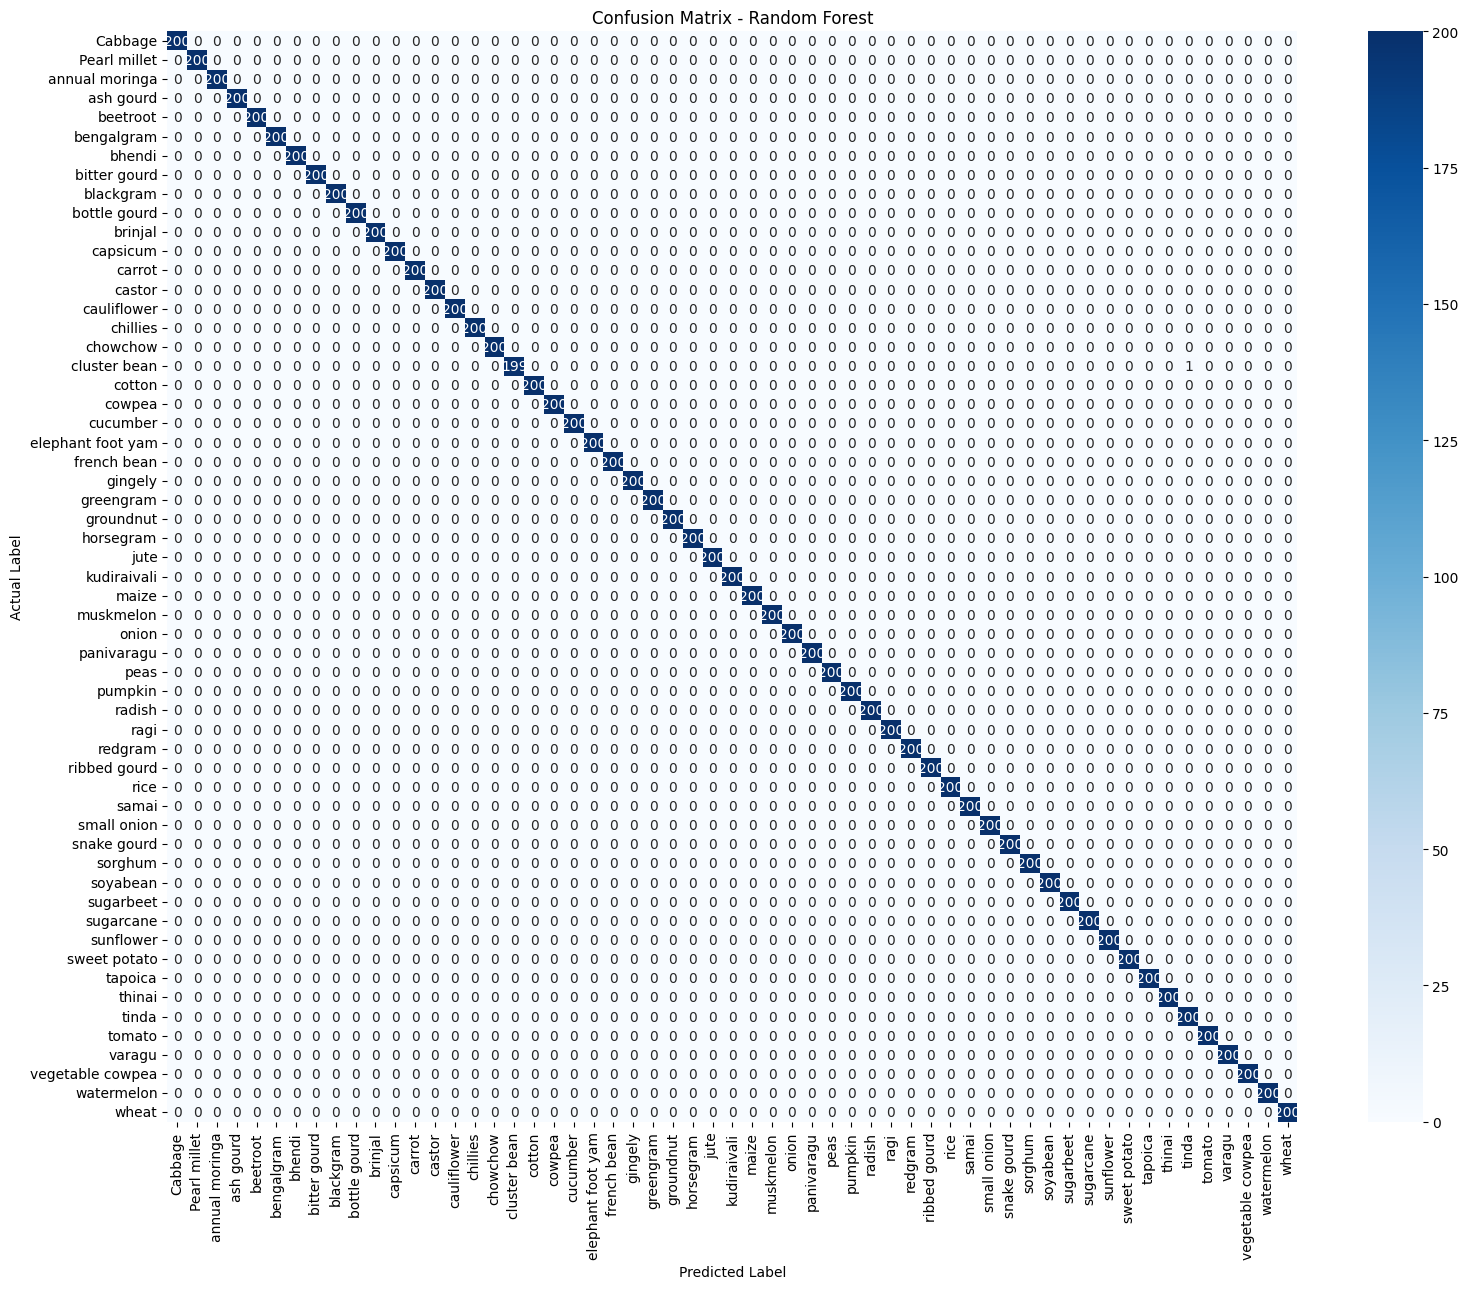

In [28]:
cm = best_result[
    "Confusion Matrix"
]

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

## Cell 29 — Per-Class F1 Score

In [29]:
report = classification_report(
    y_test,
    best_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

class_f1 = pd.DataFrame({

    "Crop":
        label_encoder.classes_,

    "F1 Score": [
        report[c]["f1-score"]
        for c in label_encoder.classes_
    ]
})

class_f1 = class_f1.sort_values(
    by="F1 Score"
)

class_f1

,Crop,F1 Score
17,cluster bean,0.997494
51,tinda,0.997506
2,annual moringa,1.000000
0,Cabbage,1.000000
4,beetroot,1.000000
5,bengalgram,1.000000
6,bhendi,1.000000
1,Pearl millet,1.000000
8,blackgram,1.000000
9,bottle gourd,1.000000


## Cell 30 — Per-Class F1 Graph

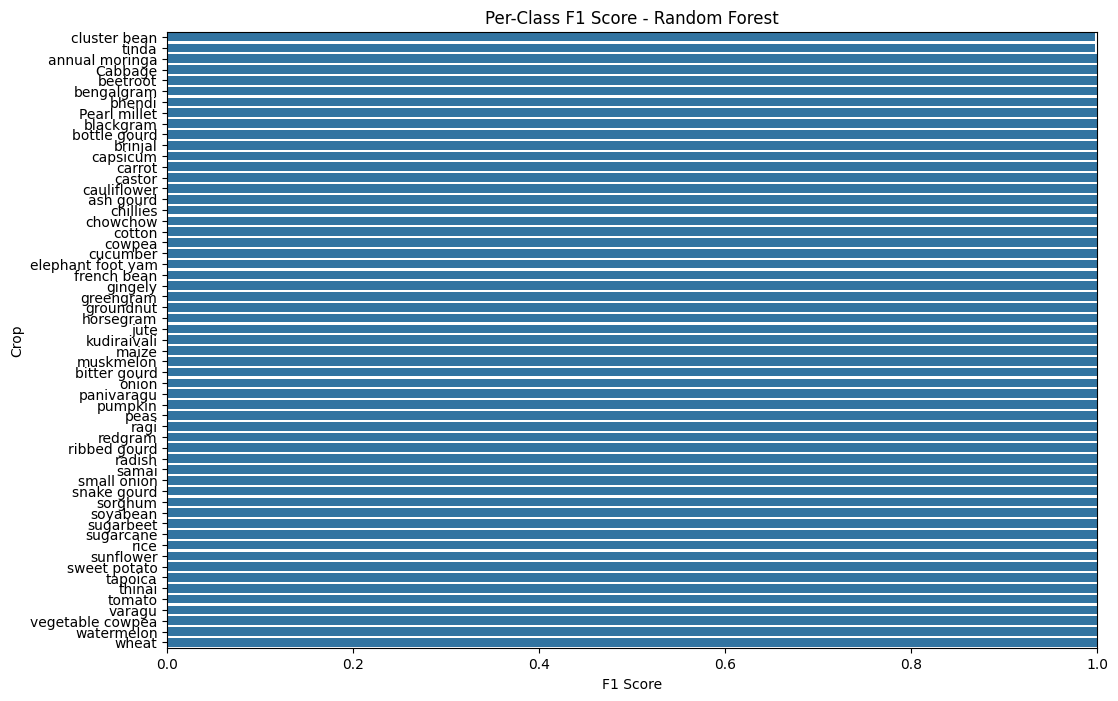

In [30]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=class_f1,
    x="F1 Score",
    y="Crop"
)

plt.title(f"Per-Class F1 Score - {best_model_name}")
plt.xlabel("F1 Score")
plt.ylabel("Crop")
plt.xlim(0, 1)

plt.show()

## Cell 31 — Feature Importance
After one-hot encoding, feature names come from the fitted `ColumnTransformer` (`get_feature_names_out()`), not the original `all_features` list.

,Feature,Importance
1,num__CROPDURATION,0.160641
4,num__RELATIVE_HUMIDITY,0.115368
3,num__WATERREQUIRED,0.109702
5,num__N,0.071134
7,num__K,0.063587
0,num__SOIL_PH,0.061248
2,num__TEMP,0.060369
6,num__P,0.039387
32,cat__SOIL_sandy Loamy soil,0.034214
12,cat__SOIL_Loamy soil,0.022564


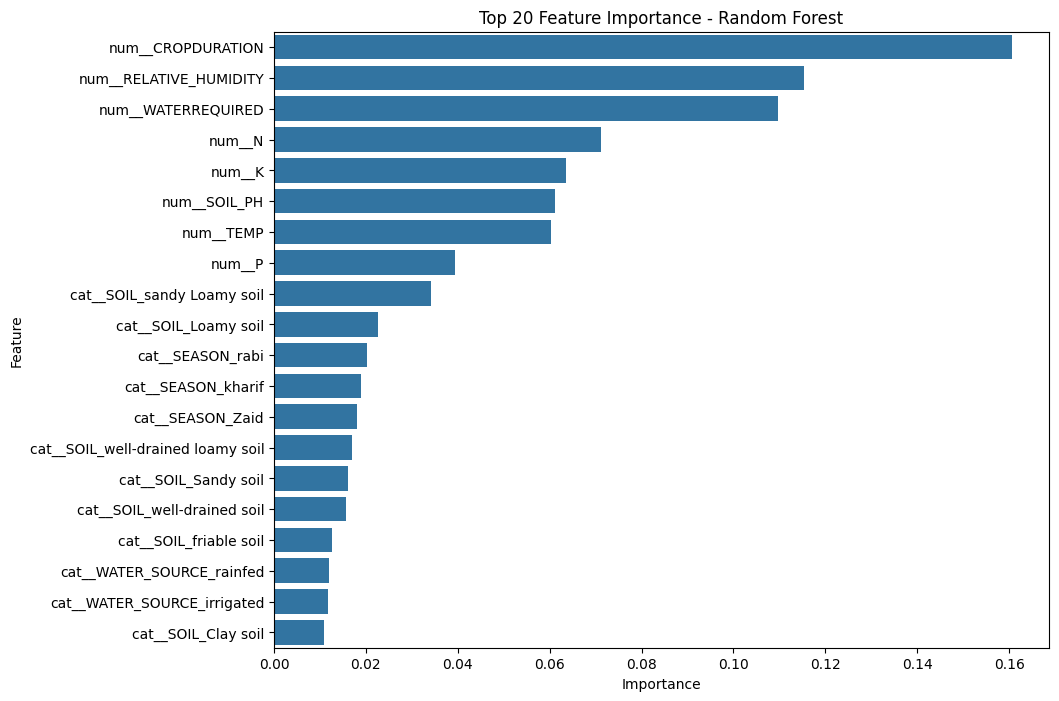

In [31]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
model_inside_pipeline = best_model.named_steps["model"]

encoded_feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(
    model_inside_pipeline,
    "feature_importances_"
):

    importance_df = pd.DataFrame({

        "Feature": encoded_feature_names,

        "Importance": model_inside_pipeline.feature_importances_

    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(20)

    display(importance_df)

    plt.figure(figsize=(10, 8))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title(f"Top 20 Feature Importance - {best_model_name}")

    plt.show()

else:

    print(
        "Feature importance is not directly "
        "available for this model."
    )

## Cell 32 — New Input
Edit the values below (only the remaining features are needed).

In [32]:
# ============================================================
# NEW INPUT — edit these values for a real prediction
# ============================================================

new_sample = {
    "SOIL_PH": 6.8,
    "CROPDURATION": 120,
    "TEMP": 27.5,
    "WATERREQUIRED": 1500,
    "RELATIVE_HUMIDITY": 68,
    "N": 85,
    "P": 45,
    "K": 45,
    "SOIL": "Alluvial soil",
    "SEASON": "kharif",
    "SOWN": "Jun",
    "HARVESTED": "Sep",
    "WATER_SOURCE": "irrigated"
}

new_data = pd.DataFrame(
    [new_sample],
    columns=all_features
)

prediction = best_model.predict(new_data)

predicted_crop = (
    label_encoder
    .inverse_transform(prediction)[0]
)

print("=" * 50)
print("🌱 Recommended Crop:", predicted_crop)
print("=" * 50)

🌱 Recommended Crop: rice


## Cell 33 — Top 3 Recommendations

In [33]:
if hasattr(best_model, "predict_proba"):

    probabilities = best_model.predict_proba(new_data)[0]

    top_indices = np.argsort(probabilities)[::-1][:3]

    print("=" * 50)
    print("🌱 TOP 3 CROP RECOMMENDATIONS")
    print("=" * 50)

    for rank, index in enumerate(top_indices, start=1):

        crop_name = label_encoder.classes_[index]
        probability = probabilities[index] * 100

        print(f"{rank}. {crop_name} → {probability:.2f}%")

else:

    print("Probability is not available for this model.")

🌱 TOP 3 CROP RECOMMENDATIONS
1. rice → 99.00%
2. cotton → 1.00%
3. watermelon → 0.00%


## Cell 34 — Save Model

In [34]:
with open("best_crop_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

with open("crop_label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)

print("Best model saved successfully!")

Best model saved successfully!


## Cell 35 — Save Model Comparison

In [35]:
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


## 🏆 Final Output — Best Crop

In [36]:
print("=" * 60)
print("🏆 BEST MODEL :", best_model_name)
print("=" * 60)

if hasattr(best_model, "predict_proba"):
    probs = best_model.predict_proba(new_data)[0]
    top = np.argsort(probs)[::-1][:3]
    best_crop = label_encoder.classes_[top[0]]
    print(f"🌾 BEST CROP : {best_crop.upper()}  ({probs[top[0]] * 100:.2f}% confidence)")
    print("\nTop 3 recommendations:")
    for r, i in enumerate(top, 1):
        print(f"  {r}. {label_encoder.classes_[i]} → {probs[i] * 100:.2f}%")
else:
    best_crop = predicted_crop
    print("🌾 BEST CROP :", best_crop.upper())

print("=" * 60)

🏆 BEST MODEL : Random Forest
🌾 BEST CROP : RICE  (99.00% confidence)

Top 3 recommendations:
  1. rice → 99.00%
  2. cotton → 1.00%
  3. watermelon → 0.00%
